# Paper Figures: Figure 1 - Movement (SIMBA) Analysis

This notebook generates publication-ready figures for the Bazzino & Roitman sodium appetite manuscript using data assembled by `src/assemble_all_data.py`.

**Figure 1: Behavioral (SIMBA) Analysis** — SIMBA analysis (appetitive) showing heatmaps and summary plots for replete and deplete conditions across sodium concentrations.

In [1]:
%load_ext IPython.extensions.autoreload
%autoreload 2

import pathlib
from pathlib import Path
import sys
# Add src to path for importing local modules
sys.path.insert(0, str(Path("../src").resolve()))
from data_io import load_assembled

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import seaborn as sns

from scipy import stats
from scipy.ndimage import gaussian_filter1d
from scipy.spatial.distance import cdist

from sklearn.manifold import MDS
from sklearn.metrics import (
    confusion_matrix,
    ConfusionMatrixDisplay,
    classification_report,
    accuracy_score
)

from trompy import zscore, save_figure_atomic
from extract_behav_parameters import smooth_array

from distance_matrix import (
    make_metric_matrix, get_group_matrix_diffs,
    GROUP_ORDER, GROUP_LABELS,
    compute_mds_coordinates,
    prepare_metric_classification_data,
    classify_groups_from_metric,
    evaluate_group_classifier_leave_one_rat_out,
 )

from figure_config import (
    configure_matplotlib, COLORS, HEATMAP_CMAP_DIV,
    HEATMAP_CMAP_RED, HEATMAP_CMAP_BLUE,
    DATAFOLDER, RESULTSFOLDER, FIGSFOLDER,
    HEATMAP_VLIM_BEHAV, YLIMS_BEHAV,
    BEHAV_SMOOTH_WINDOW, SAVE_FIGS
)
from figure_plotting import (
    smooth_array, get_heatmap_data, get_mean_snips, get_auc,
    init_heatmap_figure, init_snips_figure, make_heatmap,
    plot_snips, plot_auc_summary, print_auc_stats,
    scale_vlim_to_data, calculate_ylims,
    draw_regression_line, make_correlation_plot_simba,
    make_correlation_plot_simba_1group, make_mds_plot,
    make_euclidean_distance_heatmap_all_rats, make_euclidean_distance_heatmap_averaged,
    make_confusion_matrix
)

# Configure matplotlib
configure_matplotlib()
colors = COLORS  # Use shared color palette
custom_cmap_red = HEATMAP_CMAP_RED  # Use shared colormap
custom_cmap_blue = HEATMAP_CMAP_BLUE  # Use shared colormap

custom_cmap = HEATMAP_CMAP_DIV  # Use shared diverging colormap

SAVE_FIGS = True
SIMBA_METRIC = "median" # other options...

Failed to read module file 'c:\Users\jmc010\Github\bazzino\.pixi\envs\default\Lib\functools.py' for module 'functools': UnicodeDecodeError
Traceback (most recent call last):
  File "c:\Users\jmc010\Github\bazzino\.pixi\envs\default\Lib\site-packages\IPython\extensions\deduperreload\deduperreload.py", line 219, in update_sources
    self.source_by_modname[new_modname] = f.read()
                                          ^^^^^^^^
  File "c:\Users\jmc010\Github\bazzino\.pixi\envs\default\Lib\encodings\cp1252.py", line 23, in decode
    return codecs.charmap_decode(input,self.errors,decoding_table)[0]
           ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
UnicodeDecodeError: 'charmap' codec can't decode byte 0x81 in position 301: character maps to <undefined>
Failed to read module file 'c:\Users\jmc010\Github\bazzino\.pixi\envs\default\Lib\shlex.py' for module 'shlex': UnicodeDecodeError
Traceback (most recent call last):
  File "c:\Users\jmc010\Github\bazzino\.pixi\envs\defaul

## Load Assembled Data

Load the complete dataset from the pickle file generated by the assembly script.

In [3]:
assembled_data_path = DATAFOLDER / "assembled"

data = load_assembled(assembled_data_path)

# Extract main components
x_array = data["x_array"]
snips_photo = data["snips_photo"]

if SIMBA_METRIC == "zscore":
    snips_simba = data["snips_simba_zscore"]
    simba_col = "simba_zscore_mean"
elif SIMBA_METRIC == "median":
    snips_simba = data["snips_simba_shifted_baseline"]
    simba_col = "simba_median_balance"
elif SIMBA_METRIC == "raw":
    snips_simba = data["snips_simba_raw"]
    simba_col = "simba_raw_mean"
    custom_cmap = HEATMAP_CMAP_RED  # Use red colormap for raw metric
else:
    raise ValueError(f"Unknown SIMBA_METRIC: {SIMBA_METRIC}")

fits_df = data["fits_df"]
params = data.get("params", {})
metadata = data.get("metadata", {})

print(f"Loaded assembled data from {assembled_data_path}")
print(f"\nData structure:")
print(f"  - x_array shape: {x_array.shape}")
print(f"  - snips_photo shape: {snips_photo.shape}")
print(f"  - snips_simba shape: {snips_simba.shape}")
print(f"  - x_array columns: {x_array.columns.tolist()}")
print(f"  - Number of trials: {len(x_array)}")

Loaded assembled data from C:\Users\jmc010\Github\bazzino\data\assembled_data.pickle

Data structure:
  - x_array shape: (1960, 30)
  - snips_photo shape: (1960, 200)
  - snips_simba shape: (1960, 200)
  - x_array columns: ['trial', 'id', 'condition', 'infusiontype', 'sex', 'movement_mean', 'movement_std', 'angvel_mean', 'angvel_std', 'simba_raw_mean', 'simba_zscore_mean', 'simba_median_balance', 'simba_median_balance_binarized', 'simba_median_balance_quantized', 'cluster_photo', 'clusterness_photo', 'euclidean_diff', 'auc_snips', 'auc_snips_early', 'auc_snips_late', 'auc_movement', 'auc_angvel', 'time_moving', 'time_above_angvel_threshold', 'time_moving_raw', 'realigned_trials_da', 'realigned_trials_da_velocity', 'realigned_trials_da_cluster', 'realigned_trials_behav', 'trial_aligned']
  - Number of trials: 1960


In [4]:
data.keys()

dict_keys(['x_array', 'snips_photo', 'snips_simba_raw', 'snips_simba_shifted_baseline', 'snips_simba_zscore', 'snips_simba_baseline', 'snips_simba', 'snips_movement', 'snips_angvel', 'pca_transformed', 'fits_df', 'fits_df_da', 'fits_df_da_velocity', 'fits_df_da_cluster', 'fits_df_behav', 'z_dep45', 'metadata', 'params', 'behav_stats', 'snips_movement_raw'])

## Figure 1: Behavioral Analysis — SIMBA Metrics

Analysis of behavioral responses (movement) showing heatmaps, snip time series, and summary AUC metrics across replete and deplete sodium conditions, separated by infusion type (10NaCl vs 45NaCl).

In [5]:
snips_to_plot = np.array(smooth_array(snips_simba))  # Use smoothed and z-scored data for all subsequent analyses and plotting

# Parameters for visualization - MOVEMENT
# Use dynamic scaling based on actual data ranges (asymmetric, not symmetric)
# This ensures heatmaps use the full range of your data without artificial symmetry
vmin = np.nanpercentile(snips_to_plot, 5)  # 5th percentile for lower bound
vmax = np.nanpercentile(snips_to_plot, 95)  # 95th percentile for upper bound
print(f"Calculated asymmetric vlims: vmin={vmin:.4f}, vmax={vmax:.4f}")

if SIMBA_METRIC == "zscore":
    vlim = (-1, 1)
elif SIMBA_METRIC == "median":
    vlim = (-0.2, 0.2)
elif SIMBA_METRIC == "raw":
    vlim = (0, 0.4)  # Use calculated asymmetric limits for raw metric
else:
    vlim = (vmin, vmax)  # Use calculated asymmetric limits for other metrics

# Calculate dynamic y-limits based on all snips data - MOVEMENT
print("\n" + "="*60)
print("CALCULATING Y-LIMITS FOR TIME SERIES PLOTS")
print("="*60)

# Get all condition/infusion combinations to compute limits
rep_10, rep_45 = get_mean_snips(snips_to_plot, x_array, "replete")
dep_10, dep_45 = get_mean_snips(snips_to_plot, x_array, "deplete")

# Calculate y-limits based on all snips with 5% padding
calc_ylims = calculate_ylims([rep_10, rep_45, dep_10, dep_45], pad_percentage=5)

print(f"  Data range (min, max): ({np.nanmin(snips_to_plot):.4f}, {np.nanmax(snips_to_plot):.4f})")
print(f"  Calculated y-limits: {calc_ylims}")
print("="*60 + "\n")



Calculated asymmetric vlims: vmin=-0.1680, vmax=0.2795

CALCULATING Y-LIMITS FOR TIME SERIES PLOTS
  Data range (min, max): (-0.3044, 0.6933)
  Calculated y-limits: (np.float64(-0.15188435147959184), np.float64(0.24586074127551028))



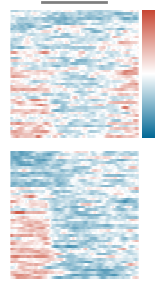

In [6]:
### 1A. Heatmaps — Replete Condition

f, ax1, ax2, cbar_ax = init_heatmap_figure()

# Replete + 10NaCl
heatmap_data_rep_10 = get_heatmap_data(snips_to_plot, x_array, "replete", "10NaCl")
replete_10_auc = get_auc(heatmap_data_rep_10)
make_heatmap(heatmap_data_rep_10, ax1, vlim, inf_bar=True, cmap=custom_cmap)

# Replete + 45NaCl
heatmap_data_rep_45 = get_heatmap_data(snips_to_plot, x_array, "replete", "45NaCl")
replete_45_auc = get_auc(heatmap_data_rep_45)
make_heatmap(heatmap_data_rep_45, ax2, vlim, cbar_ax=cbar_ax, cmap=custom_cmap)

if SAVE_FIGS:
    save_figure_atomic(f, "fig1_heatmap_simba_replete", FIGSFOLDER)

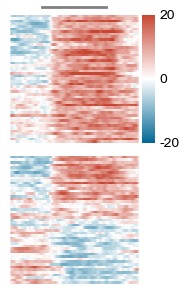

In [7]:
### 1B. Heatmaps — Deplete Condition

f, ax1, ax2, cbar_ax = init_heatmap_figure()

# Deplete + 10NaCl
heatmap_data_dep_10 = get_heatmap_data(snips_to_plot, x_array, "deplete", "10NaCl")
deplete_10_auc = get_auc(heatmap_data_dep_10)
make_heatmap(heatmap_data_dep_10, ax1, vlim, inf_bar=True, cmap=custom_cmap)

# Deplete + 45NaCl
heatmap_data_dep_45 = get_heatmap_data(snips_to_plot, x_array, "deplete", "45NaCl")
deplete_45_auc = get_auc(heatmap_data_dep_45)
make_heatmap(heatmap_data_dep_45, ax2, vlim, cbar_ax=cbar_ax, cmap=custom_cmap)

cbar_ax.tick_params(axis='both', length=0)
if SIMBA_METRIC == "zscore":
    cbar_ax.set_yticks((-1, 0, 1), labels=["-1", "0", "1"])
elif SIMBA_METRIC == "median":
    cbar_ax.set_yticks((-0.2, 0, 0.2), labels=["-20", "0", "20"])
elif SIMBA_METRIC == "raw":
    cbar_ax.set_yticks((0, 0.4))

if SAVE_FIGS:
    save_figure_atomic(f, "fig1_heatmap_simba_deplete", FIGSFOLDER)

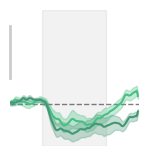

In [8]:
### 1C. Time Series Snips — Replete Condition
if SIMBA_METRIC == "zscore":
    ylims = (-0.5, 1)
    yscalebar=[0.3, 0.8]
elif SIMBA_METRIC == "median":
    ylims = (-0.08, 0.18)
    yscalebar=[0.05, 0.15]
elif SIMBA_METRIC == "raw":
    ylims = (0, 0.4)
    yscalebar=[0.1, 0.3]
else:
    ylims = calc_ylims
    yscalebar=[0.3, 0.8]
    
# Get animal-averaged snips for replete
snips_rep_10, snips_rep_45 = get_mean_snips(snips_to_plot, x_array, "replete")

f, ax = init_snips_figure()
plot_snips(snips_rep_10, snips_rep_45, ax, colors[0], colors[1], ylims, yscalebar=yscalebar, xscalebar=False)
ax.axhline(0, color="black", lw=1, ls="--", alpha=0.5, zorder=0)
ax.axvspan(5, 15, color="k", alpha=0.05, zorder=-10)

if SAVE_FIGS:
    save_figure_atomic(f, "fig1_snips_simba_replete", FIGSFOLDER)

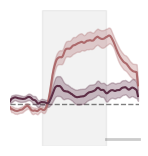

In [9]:
### 1D. Time Series Snips — Deplete Condition

# Get animal-averaged snips for deplete
snips_dep_10, snips_dep_45 = get_mean_snips(snips_to_plot, x_array, "deplete")

f, ax = init_snips_figure()
plot_snips(snips_dep_10, snips_dep_45, ax, colors[2], colors[3], ylims, xscalebar=True)  # Add scale bar for deplete condition
ax.axhline(0, color="black", lw=1, ls="--", alpha=0.5, zorder=0)
ax.axvspan(5, 15, color="k", alpha=0.05, zorder=-10)

if SAVE_FIGS:
    save_figure_atomic(f, "fig1_snips_simba_deplete", FIGSFOLDER)

In [ ]:
### 1E. AUC Summary — Bar Plot with Individual Data Points

def get_auc_and_sex_by_group(x_array, condition, infusiontype, simba_col="mean_simba"):
    grouped = (
        x_array
        .query("condition == @condition and infusiontype == @infusiontype")
        .groupby("id", sort=True)
        .agg(
            simba_col=(simba_col, "mean"),
            sex=("sex", "first"),
        )
    )
    auc_vals = grouped["simba_col"].to_numpy()
    sex_vals = grouped["sex"].fillna("Unknown").to_numpy()
    return auc_vals, sex_vals

ylabel = "Mean valence Index"

# Organize AUCs by condition
replete_10_auc, replete_10_sex = get_auc_and_sex_by_group(x_array, "replete", "10NaCl", simba_col=simba_col)
replete_45_auc, replete_45_sex = get_auc_and_sex_by_group(x_array, "replete", "45NaCl", simba_col=simba_col)
deplete_10_auc, deplete_10_sex = get_auc_and_sex_by_group(x_array, "deplete", "10NaCl", simba_col=simba_col)
deplete_45_auc, deplete_45_sex = get_auc_and_sex_by_group(x_array, "deplete", "45NaCl", simba_col=simba_col)

replete_aucs = [replete_10_auc, replete_45_auc]
deplete_aucs = [deplete_10_auc, deplete_45_auc]
aucs = [replete_aucs, deplete_aucs]

sex_groups = [
    [replete_10_sex, replete_45_sex],
    [deplete_10_sex, deplete_45_sex],
]

f, ax = plot_auc_summary(
    aucs,
    colors,
    figsize=(2.2, 2.2),
    ylabel=ylabel,
    sex_groups=sex_groups,
    sex_markers={"M": "^", "F": "o"}
 )

if SAVE_FIGS:
    save_figure_atomic(f, "fig1_auc_simba_summary", FIGSFOLDER)

In [ ]:
# 1E stats: one-sample tests against zero (no sex factor)
from stats_helpers import (
    one_sample_wilcoxon_table,
    prepare_mixedlm_auc_df,
    fit_mixedlm_with_fallback,
    omnibus_wald_table,
    posthoc_pairwise_auc,
    holm_matrix_from_posthoc,
)

# We evaluated both parametric and non-parametric one-sample approaches.
# Non-parametric testing was more appropriate for these AUC distributions,
# so we use Wilcoxon signed-rank tests for all groups for consistency.
group_data = {
    "Replete + 10NaCl": replete_aucs[0],
    "Replete + 45NaCl": replete_aucs[1],
    "Deplete + 10NaCl": deplete_aucs[0],
    "Deplete + 45NaCl": deplete_aucs[1],
}

stats_df = one_sample_wilcoxon_table(group_data)
print("Figure 1E — One-sample Wilcoxon signed-rank tests against zero (sex not included as a factor)")
display(stats_df)

In [ ]:
# 1E omnibus model (ANOVA-like): condition within-subject, infusiontype/sex between-subject
# Build subject-by-condition dataset from averaged SIMBA metric
model_df = prepare_mixedlm_auc_df(x_array, value_col=simba_col)

print(f"Subjects included in omnibus model: {model_df['id'].nunique()}")
print(f"Rows (subject x condition): {len(model_df)}")

mixed_res, model_formula_used, model_fit_errors = fit_mixedlm_with_fallback(model_df)
if mixed_res is None:
    print("\nFigure 1E omnibus model could not be fit (all candidate models failed).")
    print("Model-fit errors:")
    for formula, err in model_fit_errors:
        print(f"  - {formula}: {err}")
else:
    print(f"\nFigure 1E omnibus model fitted with formula: {model_formula_used}")
    print("Fixed-effects omnibus tests (Wald):")
    try:
        display(omnibus_wald_table(mixed_res))
    except Exception:
        print("wald_test_terms not available; showing fixed-effects coefficient table instead.")
        display(mixed_res.summary().tables[1])

In [ ]:
# 1E mixed ANOVA: condition (within) × infusiontype × sex (between)
# 3-way interaction (condition × infusiontype × sex) excluded — sex is included
# as a main effect and in 2-way interactions but the 3-way is pooled into error.
#
# Implemented via OLS decomposition (mathematically equivalent to standard mixed ANOVA):
#   Between-subjects effects  →  OLS on per-subject means (collapsed over condition)
#   Within-subjects effects   →  OLS on condition contrast (deplete − replete)

import statsmodels.formula.api as smf
from statsmodels.stats.anova import anova_lm
import numpy as np
import pandas as pd
from scipy import stats

# Pivot to wide format: one row per subject
wide_df = model_df.pivot_table(
    index=["id", "infusiontype", "sex"],
    columns="condition",
    values="auc",
).reset_index()
wide_df.columns.name = None
n_s = len(wide_df)

# Between-subjects partition: OLS on per-subject means
# Full factorial between factors (infusiontype × sex interaction retained)
wide_df["subj_mean"] = wide_df[["replete", "deplete"]].mean(axis=1)
bw_fit = smf.ols("subj_mean ~ C(infusiontype) * C(sex)", data=wide_df).fit()

# Within-subjects partition: OLS on condition contrast (deplete − replete)
# No 3-way: use additive model for within × between interactions
wide_df["cond_diff"] = wide_df["deplete"] - wide_df["replete"]
wi_fit = smf.ols("cond_diff ~ C(infusiontype) + C(sex)", data=wide_df).fit()

# Condition main effect F (computed manually from the within-subjects error)
mean_d = wide_df["cond_diff"].mean()
F_C = n_s * mean_d ** 2 / wi_fit.mse_resid
p_C = stats.f.sf(F_C, dfn=1, dfd=wi_fit.df_resid)

def _label(s):
    return (s.replace("C(infusiontype)", "infusiontype")
             .replace("C(sex)", "sex")
             .replace(":", " × "))

rows = []
for src, row in anova_lm(bw_fit, typ=2).iterrows():
    if src == "Residual":
        rows.append({"Source": "  Error (between-subjects)", "df": int(row["df"]),
                     "F": np.nan, "p": np.nan})
    else:
        rows.append({"Source": _label(src), "df": int(row["df"]),
                     "F": row["F"], "p": row["PR(>F)"]})

rows.append({"Source": "condition", "df": 1, "F": F_C, "p": p_C})

for src, row in anova_lm(wi_fit, typ=2).iterrows():
    if src == "Residual":
        rows.append({"Source": "  Error (within-subjects)", "df": int(row["df"]),
                     "F": np.nan, "p": np.nan})
    else:
        rows.append({"Source": "condition × " + _label(src), "df": int(row["df"]),
                     "F": row["F"], "p": row["PR(>F)"]})

aov_table = pd.DataFrame(rows).set_index("Source")

print("Mixed ANOVA  (condition: within | infusiontype, sex: between; 3-way interaction excluded)")
print(f"N = {n_s} subjects | Between-error df = {int(bw_fit.df_resid)} | "
      f"Within-error df = {int(wi_fit.df_resid)}\n")
display(aov_table.round(4))

In [ ]:
# Export JASP-ready data for mixed ANOVA
# Saves both wide (recommended for repeated-measures setup in JASP) and long formats.

jasp_outdir = RESULTSFOLDER
jasp_outdir.mkdir(parents=True, exist_ok=True)

# Wide format: one row per subject, between factors as columns,
# repeated-measures levels as separate dependent-variable columns.
jasp_wide = (
    model_df
    .pivot_table(index=["id", "infusiontype", "sex"], columns="condition", values="auc")
    .reset_index()
)
jasp_wide.columns.name = None
jasp_wide = jasp_wide.rename(columns={
    "replete": "auc_replete",
    "deplete": "auc_deplete",
})

# Long format: one row per subject x condition
jasp_long = model_df[["id", "infusiontype", "sex", "condition", "auc"]].copy()

wide_path = jasp_outdir / "figure1_mixed_anova_jasp_wide.csv"
long_path = jasp_outdir / "figure1_mixed_anova_jasp_long.csv"

jasp_wide.to_csv(wide_path, index=False)
jasp_long.to_csv(long_path, index=False)

print("Saved JASP export files:")
print(f"  - {wide_path}")
print(f"  - {long_path}")
print("\nWide format columns:", list(jasp_wide.columns))
print("Long format columns:", list(jasp_long.columns))

display(jasp_wide.head())

In [ ]:
# 1E posthoc pairwise tests across 4 groups (ignoring sex) with multiple-comparison correction
posthoc_results, groups = posthoc_pairwise_auc(x_array, value_col=simba_col)

print("Posthoc pairwise tests across 4 groups (sex ignored), Holm-corrected")
display(posthoc_results.sort_values("p_holm", na_position="last"))

# Compact 4x4 matrix view of Holm-adjusted p-values
p_matrix = holm_matrix_from_posthoc(posthoc_results, groups)
print("\nCompact matrix: Holm-adjusted p-values")
display(p_matrix)

In [ ]:
### Correlation plots — Time moving across trials

def make_auc_data_per_trial(x_array, condition, infusiontype, simba_col):
    return (
        x_array
        .query("condition == @condition & infusiontype == @infusiontype")
        .groupby("trial")[simba_col]
        .mean()
        .values
    )
    
replete_10 = make_auc_data_per_trial(x_array, "replete", "10NaCl", simba_col)
replete_45 = make_auc_data_per_trial(x_array, "replete", "45NaCl", simba_col)
deplete_10 = make_auc_data_per_trial(x_array, "deplete", "10NaCl", simba_col)
deplete_45 = make_auc_data_per_trial(x_array, "deplete", "45NaCl", simba_col)

# f = make_correlation_plot_simba(replete_10, replete_45, colors[0], colors[1], yaxis=True)
# if SAVE_FIGS:
#     save_figure_atomic(f, "fig1_correlation_simba_replete", FIGSFOLDER)
    
# f = make_correlation_plot_simba(deplete_10, deplete_45, colors[2], colors[3])
# if SAVE_FIGS:
#     save_figure_atomic(f, "fig1_correlation_simba_deplete", FIGSFOLDER)

In [ ]:
f, ax = make_correlation_plot_simba_1group(replete_10, colors[0], yaxis=True, simba_metric=SIMBA_METRIC)
if SAVE_FIGS:
    save_figure_atomic(f, "fig1_correlation_simba_replete10", FIGSFOLDER)
    
f, ax = make_correlation_plot_simba_1group(replete_45, colors[1], simba_metric=SIMBA_METRIC)
if SAVE_FIGS:
    save_figure_atomic(f, "fig1_correlation_simba_replete45", FIGSFOLDER)
    
f, ax = make_correlation_plot_simba_1group(deplete_10, colors[2], simba_metric=SIMBA_METRIC)
if SAVE_FIGS:
    save_figure_atomic(f, "fig1_correlation_simba_deplete10", FIGSFOLDER)
    
f, ax = make_correlation_plot_simba_1group(deplete_45, colors[3], fit="sigmoid", simba_metric=SIMBA_METRIC)
if SAVE_FIGS:
    save_figure_atomic(f, "fig1_correlation_simba_deplete45", FIGSFOLDER)

In [ ]:
### Model fits on time-moving by trial data with fit-quality checks
from model_fit_helpers import run_model_fit_comparison

fit_inputs = {
    "Replete + 10NaCl": replete_10,
    "Replete + 45NaCl": replete_45,
    "Deplete + 10NaCl": deplete_10,
    "Deplete + 45NaCl": deplete_45,
}

fit_results, sigmoid_params_table = run_model_fit_comparison(
    fit_inputs,
    models=("linear", "sigmoidal"),
)

print("Model fit results (AUC_simba by trial; linear + sigmoidal only) with quality checks:")
display(fit_results)

print("Sigmoidal fit parameters (AUC_simba by trial) with validity checks:")
display(sigmoid_params_table)

In [ ]:
### Best valid model per condition (compact summary)
from model_fit_helpers import summarize_best_valid_model

best_model_summary = summarize_best_valid_model(fit_results)

print("Best valid model per condition (AICc-based):")
display(best_model_summary)

## Euclidean distances

In [ ]:
# prepare distance matrix for heatplots and MDS plot
matrix, series_labels, _, group_to_row_indices = make_metric_matrix(x_array, "simba_median_balance", GROUP_ORDER, GROUP_LABELS)

group_sizes = {GROUP_LABELS[group_key]: len(indices) for group_key, indices in group_to_row_indices.items()}
group_boundaries = np.cumsum([len(group_to_row_indices[group_key]) for group_key in GROUP_ORDER])

distances, group_distance_matrix = get_group_matrix_diffs(matrix, series_labels, group_to_row_indices)

In [ ]:
# make euclidiean distance heatplots

fig, ax = make_euclidean_distance_heatmap_all_rats(distances, group_boundaries=group_boundaries)
if SAVE_FIGS:
    save_figure_atomic(fig, "fig1_heatmap_euclidean_all_rats", FIGSFOLDER)
    
# Toggle redundant annotation labels on/off for symmetric matrix plots.
# keep_triangle options: "upper" or "lower"
fig, ax, fig_cbar, ax_cbar = make_euclidean_distance_heatmap_averaged(
    group_distance_matrix,
    remove_redundant_labels=True,
    keep_triangle="upper",
 )
ax_cbar.set_ylim([4,7])

if SAVE_FIGS:
    save_figure_atomic(fig, "fig1_heatmap_euclidean_averaged", FIGSFOLDER)
    save_figure_atomic(fig_cbar, "fig1_heatmap_euclidean_averaged_cbar", FIGSFOLDER)

In [ ]:
# make MDS plot for photometry data
coords = compute_mds_coordinates(distances)

fig, ax = make_mds_plot(coords, group_to_row_indices, reverse_axes="x")

if SAVE_FIGS:
    save_figure_atomic(fig, "fig1_mds_plot", FIGSFOLDER)

In [ ]:
# use classifier to predict group labels from behaviour data and make confusion matrix

metric_col = "simba_median_balance"
results = classify_groups_from_metric(
    x_array=x_array,
    metric_col=metric_col,
    group_order=GROUP_ORDER,
    group_labels=GROUP_LABELS,
    smooth_features=False,
    expected_n_trials=49,
    normalize="true",
)

X = results["X"]
y = results["y"]
rat_groups = results["rat_groups"]
metric_matrix_df = results["metric_matrix_df"]
cm = results["cm"]

print("Feature matrix shape (n_samples, n_trials):", X.shape)
print("Unique class labels:", np.unique(y))
print("Unique rats:", len(np.unique(rat_groups)))
print(f"Leave-One-Rat-Out CV accuracy: {results['accuracy']:.3f}")
print(results["report_text"])

# Toggle redundant annotation labels on/off for symmetric matrix plots.
# keep_triangle options: "upper" or "lower"
fig, ax, fig_cbar, ax_cbar = make_confusion_matrix(
    cm,
)
save_figure_atomic(fig, "fig1_confusion_matrix", FIGSFOLDER)

ax_cbar.set_yticks([])
save_figure_atomic(fig_cbar, "fig1_confusion_matrix_cbar", FIGSFOLDER)

In [ ]:
# Binomial test: classifier accuracy vs chance level
from scipy.stats import binomtest

n_total = len(y)
n_classes = len(np.unique(y))
chance_level = 1.0 / n_classes
n_correct = int(round(results["accuracy"] * n_total))

binom_res = binomtest(k=n_correct, n=n_total, p=chance_level, alternative="greater")

print(f"n_total = {n_total}")
print(f"n_correct = {n_correct}")
print(f"accuracy = {results['accuracy']:.3f}")
print(f"chance level = {chance_level:.3f}")
print(f"one-sided binomial p-value = {binom_res.pvalue:.12g}")

In [ ]:
### Figure 1 legend swatches (pie-style legend exports)

from matplotlib.patches import Patch

groups = ["", ""]

# Replete swatches (match archived spacing/placement exactly)
f, ax = plt.subplots(figsize=(0.35, 0.25), gridspec_kw={"left": 0.01, "right": 0.99})

legend_patches = []
for color, text in zip(colors[:2], groups):
    patch = Patch(color=color, label=text)
    legend_patches.append(patch)

ax.legend(
    handles=legend_patches,
    loc="center",
    fontsize=8,
    frameon=False,
    labelspacing=0.2,
    borderpad=0.05,
    )
ax.axis("off")

if SAVE_FIGS:
    f.savefig(FIGSFOLDER / "legend_pies_replete.pdf", dpi=600, transparent=True)

# Deplete swatches (match archived spacing/placement exactly)
f, ax = plt.subplots(figsize=(0.35, 0.25), gridspec_kw={"left": 0.01, "right": 0.99})

legend_patches = []
for color, text in zip(colors[2:], groups):
    patch = Patch(color=color, label=text)
    legend_patches.append(patch)

ax.legend(
    handles=legend_patches,
    loc="center",
    fontsize=8,
    frameon=False,
    labelspacing=0.2,
    borderpad=0.05,
    )
ax.axis("off")

if SAVE_FIGS:
    f.savefig(FIGSFOLDER / "legend_pies_deplete.pdf", dpi=600, transparent=True)

print("Saved legend swatch figures:")
print("  - legend_pies_replete.pdf")
print("  - legend_pies_deplete.pdf")